# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo
- Alumno 1 : **Alejandro Armas**
- Alumno 2 : **Gabriel Soda**

In [30]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
from IPython.display import display
import warnings

import altair as alt
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

alt.data_transformers.disable_max_rows()

DATA_DIR = Path("data/images")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

In [31]:
# Escaneamos metadatos: no cargamos todos los píxeles ni imágenes completas en memoria.
# Cada subcarpeta representa una identidad en el dataset Pins.
records = []
candidates = sorted(
    path for path in DATA_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

for path in candidates:
    identity = path.parent.name.removeprefix("pins_").strip()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error")
            with Image.open(path) as image:
                image.load()  # valida que el archivo pueda decodificarse
                width, height = image.size
                image_format, mode = image.format, image.mode
                grayscale = np.asarray(image.convert("L"), dtype=np.float32)
                brightness = grayscale.mean()
                contrast = grayscale.std()

        records.append(
            {
                "path": str(path.relative_to(DATA_DIR)),
                "identity": identity,
                "width": width,
                "height": height,
                "aspect_ratio": round(width / height, 3),
                "pixels": width * height,
                "format": image_format,
                "mode": mode,
                "brightness": round(float(brightness), 2),
                "contrast": round(float(contrast), 2),
                "readable": True,
                "error": None,
            }
        )
    except (UnidentifiedImageError, OSError, ValueError, Warning) as error:
        records.append(
            {
                "path": str(path.relative_to(DATA_DIR)),
                "identity": identity,
                "width": None, "height": None, "aspect_ratio": None, "pixels": None,
                "format": None, "mode": None, "brightness": None, "contrast": None,
                "readable": False, "error": type(error).__name__,
            }
        )

images = pl.from_dicts(records)
images.head()

path,identity,width,height,aspect_ratio,pixels,format,mode,brightness,contrast,readable,error
str,str,i64,i64,f64,i64,str,str,f64,f64,bool,null
"""pins_Adriana Lima/Adriana Lima…","""Adriana Lima""",550,668,0.823,367400,"""JPEG""","""RGB""",106.71,80.19,true,null
"""pins_Adriana Lima/Adriana Lima…","""Adriana Lima""",302,320,0.944,96640,"""JPEG""","""RGB""",117.54,67.99,true,null
"""pins_Adriana Lima/Adriana Lima…","""Adriana Lima""",146,155,0.942,22630,"""JPEG""","""RGB""",99.33,73.47,true,null
"""pins_Adriana Lima/Adriana Lima…","""Adriana Lima""",209,225,0.929,47025,"""JPEG""","""RGB""",80.84,51.97,true,null
"""pins_Adriana Lima/Adriana Lima…","""Adriana Lima""",102,108,0.944,11016,"""JPEG""","""RGB""",80.18,56.96,true,null


## EDA mínimo: distribución, resoluciones y formatos

Usamos `polars` para agregar los metadatos sin convertirlos a pandas. Los gráficos de `altair` reciben tablas ya agregadas: así la visualización sigue siendo liviana aunque el dataset tenga miles de imágenes.

In [32]:
readable = images.filter(pl.col("readable"))
identity_counts = (
    readable.group_by("identity")
    .len()
    .rename({"len": "image_count"})
    .sort("image_count", descending=True)
 )

# Una columna de Polars debe tener un solo tipo: usamos texto para esta tabla de resumen.
summary = pl.DataFrame(
    {
        "metric": [
            "Archivos candidatos", "Imágenes legibles", "Imágenes no legibles",
            "Identidades", "Imágenes por identidad (media)",
            "Imágenes por identidad (mediana)", "Mínimo / máximo por identidad",
        ],
        "value": [
            str(images.height),
            str(readable.height),
            str(images.filter(~pl.col("readable")).height),
            str(identity_counts.height),
            f"{identity_counts['image_count'].mean():.2f}",
            str(identity_counts["image_count"].median()),
            f"{identity_counts['image_count'].min()} / {identity_counts['image_count'].max()}",
        ],
    }
 )
format_counts = readable.group_by(["format", "mode"]).len().sort("len", descending=True)

display(summary)
display(format_counts)

metric,value
str,str
"""Archivos candidatos""","""17534"""
"""Imágenes legibles""","""17534"""
"""Imágenes no legibles""","""0"""
"""Identidades""","""105"""
"""Imágenes por identidad (media)""","""166.99"""
"""Imágenes por identidad (median…","""169.0"""
"""Mínimo / máximo por identidad""","""86 / 237"""


format,mode,len
str,str,u32
"""JPEG""","""RGB""",17534


In [33]:
# Estadísticas de resolución y relación de aspecto solicitadas en el punto 2.2.
resolution_stats = readable.select(
    pl.col("width").min().alias("width_min"),
    pl.col("width").median().alias("width_median"),
    pl.col("width").max().alias("width_max"),
    pl.col("height").min().alias("height_min"),
    pl.col("height").median().alias("height_median"),
    pl.col("height").max().alias("height_max"),
    pl.col("aspect_ratio").mean().round(3).alias("aspect_ratio_mean"),
    (
        (pl.col("width") < 112) | (pl.col("height") < 112)
    ).sum().alias("smaller_than_112px"),
 )
display(resolution_stats)

top_identities = identity_counts.head(20)
bottom_identities = identity_counts.tail(20).sort("image_count")

identity_chart = (
    alt.Chart(
        alt.InlineData(values=top_identities.to_dicts()),
        title="20 identidades con más imágenes",
    )
    .mark_bar()
    .encode(
        x=alt.X("image_count:Q", title="Imágenes"),
        y=alt.Y("identity:N", sort="-x", title="Identidad"),
        tooltip=["identity:N", "image_count:Q"],
    )
    .properties(width=380, height=420)
 )

bottom_identity_chart = (
    alt.Chart(
        alt.InlineData(values=bottom_identities.to_dicts()),
        title="20 identidades con menos imágenes",
    )
    .mark_bar()
    .encode(
        x=alt.X("image_count:Q", title="Imágenes"),
        y=alt.Y("identity:N", sort="x", title="Identidad"),
        tooltip=["identity:N", "image_count:Q"],
    )
    .properties(width=380, height=420)
 )

resolution_bins = (
    readable.with_columns(
        (pl.col("width") // 32 * 32).alias("width_bin"),
        (pl.col("height") // 32 * 32).alias("height_bin"),
    )
    .group_by(["width_bin", "height_bin"]).len()
    .rename({"len": "image_count"})
 )
resolution_chart = (
    alt.Chart(
        alt.InlineData(values=resolution_bins.to_dicts()),
        title="Distribución de resoluciones (bins de 32 px)",
    )
    .mark_rect()
    .encode(
        x=alt.X("width_bin:O", title="Ancho (px)"),
        y=alt.Y("height_bin:O", title="Alto (px)"),
        color=alt.Color("image_count:Q", title="Imágenes"),
        tooltip=["width_bin:Q", "height_bin:Q", "image_count:Q"],
    )
    .properties(width=420, height=420)
 )

display((identity_chart | bottom_identity_chart) & resolution_chart)

width_min,width_median,width_max,height_min,height_median,height_max,aspect_ratio_mean,smaller_than_112px
i64,f64,i64,i64,f64,i64,f64,u32
80,175.0,564,82,185.0,802,0.942,2626


alt.VConcatChart(...)

In [34]:
# Distribución de imágenes por identidad: estadísticas para medir el desbalance.
class_count_stats = identity_counts.select(
    pl.len().alias("identities"),
    pl.col("image_count").min().alias("min"),
    pl.col("image_count").quantile(0.25).alias("q1"),
    pl.col("image_count").mean().round(2).alias("mean"),
    pl.col("image_count").median().alias("median"),
    pl.col("image_count").quantile(0.75).alias("q3"),
    pl.col("image_count").max().alias("max"),
    pl.col("image_count").std().round(2).alias("std"),
    (pl.col("image_count").std() / pl.col("image_count").mean()).round(3).alias("coefficient_of_variation"),
)
display(class_count_stats)

# Para superponer KDE e histograma, escalamos la densidad por n × ancho del bin.
BIN_STEP = 20
N_CLASSES = identity_counts.height
image_count_data = alt.InlineData(values=identity_counts.to_dicts())

count_histogram = (
    alt.Chart(image_count_data, title="Imágenes por identidad: histograma y KDE")
    .mark_bar(opacity=0.55, color="#4c78a8")
    .encode(
        x=alt.X(
            "image_count:Q",
            bin=alt.Bin(step=BIN_STEP),
            title="Imágenes por identidad",
        ),
        y=alt.Y("count():Q", title="Cantidad de identidades"),
        tooltip=[alt.Tooltip("count():Q", title="Identidades")],
    )
 )

kde_chart = (
    alt.Chart(image_count_data)
    .transform_density(
        "image_count",
        as_=["image_count", "density"],
        extent=[identity_counts["image_count"].min(), identity_counts["image_count"].max()],
        steps=100,
    )
    .transform_calculate(scaled_density=f"datum.density * {N_CLASSES * BIN_STEP}")
    .mark_line(color="#e45756", strokeWidth=3)
    .encode(
        x=alt.X("image_count:Q"),
        y=alt.Y("scaled_density:Q"),
        tooltip=[
            alt.Tooltip("image_count:Q", title="Imágenes", format=".1f"),
            alt.Tooltip("scaled_density:Q", title="KDE escalada", format=".2f"),
        ],
    )
 )

display((count_histogram + kde_chart).properties(width=650, height=320))

identities,min,q1,mean,median,q3,max,std,coefficient_of_variation
u32,u32,f64,f64,f64,f64,u32,f64,f64
105,86,141.0,166.99,169.0,192.0,237,34.13,0.204


alt.LayerChart(...)

In [35]:
# Elegimos clases cercanas a la mediana, no las que tienen menos ejemplos.
# El cupo común se aplica más adelante con una semilla fija al crear los splits.
N_IDENTITIES = 20
median_count = identity_counts["image_count"].median()
subset_identities = (
    identity_counts.with_columns(
        (pl.col("image_count") - median_count).abs().alias("distance_to_median")
    )
    .sort(["distance_to_median", "image_count", "identity"])
    .head(N_IDENTITIES)
    .sort("image_count", descending=True)
 )
subset_quota = subset_identities["image_count"].min()

print(f"Mediana global: {median_count} imágenes por identidad")
print(f"Cupo equilibrado propuesto: {subset_quota} imágenes por identidad")
display(subset_identities)

subset_chart = (
    alt.Chart(
        alt.InlineData(values=subset_identities.to_dicts()),
        title=f"Subset propuesto: {N_IDENTITIES} identidades cercanas a la mediana",
    )
    .mark_bar()
    .encode(
        x=alt.X("image_count:Q", title="Imágenes disponibles"),
        y=alt.Y("identity:N", sort="-x", title="Identidad"),
        tooltip=["identity:N", "image_count:Q", "distance_to_median:Q"],
    )
    .properties(width=500, height=420)
 )
display(subset_chart)

Mediana global: 169.0 imágenes por identidad
Cupo equilibrado propuesto: 160 imágenes por identidad


identity,image_count,distance_to_median
str,u32,f64
"""Mark Ruffalo""",178,9.0
"""Miley Cyrus""",178,9.0
"""Rebecca Ferguson""",178,9.0
"""Katharine Mcphee""",177,8.0
"""Chris Pratt""",176,7.0
…,…,…
"""Eliza Taylor""",162,7.0
"""camila mendes""",162,7.0
"""Marie Avgeropoulos""",161,8.0


alt.Chart(...)

## Muestra visual y variaciones fotométricas

La grilla permite revisar visualmente diversidad de pose, expresión y oclusiones; los extremos de brillo y contraste se usan como casos difíciles cuantificables. El tamaño del rostro dentro de la imagen se evaluará después de aplicar el detector en la sección de detección y alineación: las dimensiones globales no permiten inferir el tamaño real de la cara.

In [38]:
# Si la celda de carga se ejecutó antes de agregar estas métricas, las calculamos aquí.
# Así esta sección también funciona con el DataFrame que ya estaba en memoria.
if "brightness" not in images.columns:
    photometric_records = []
    for row in images.filter(pl.col("readable")).select("path").iter_rows(named=True):
        with Image.open(DATA_DIR / row["path"]) as image:
            grayscale = np.asarray(image.convert("L"), dtype=np.float32)
        photometric_records.append(
            {
                "path": row["path"],
                "brightness": round(float(grayscale.mean()), 2),
                "contrast": round(float(grayscale.std()), 2),
            }
        )

    images = images.join(pl.DataFrame(photometric_records), on="path", how="left")
    readable = images.filter(pl.col("readable"))

photometric_stats = readable.select(
    pl.col("brightness").min().alias("brightness_min"),
    pl.col("brightness").quantile(0.25).round(2).alias("brightness_q1"),
    pl.col("brightness").median().alias("brightness_median"),
    pl.col("brightness").quantile(0.75).round(2).alias("brightness_q3"),
    pl.col("brightness").max().alias("brightness_max"),
    pl.col("contrast").min().alias("contrast_min"),
    pl.col("contrast").quantile(0.25).round(2).alias("contrast_q1"),
    pl.col("contrast").median().alias("contrast_median"),
    pl.col("contrast").quantile(0.75).round(2).alias("contrast_q3"),
    pl.col("contrast").max().alias("contrast_max"),
)
display(photometric_stats)

photometric_long = readable.unpivot(
    index=["path", "identity"],
    on=["brightness", "contrast"],
    variable_name="metric",
    value_name="value",
)
photometric_histogram = (
    alt.Chart(
        alt.InlineData(values=photometric_long.to_dicts()),
        title="Distribución de brillo y contraste",
    )
    .mark_bar(opacity=0.65)
    .encode(
        x=alt.X("value:Q", bin=alt.Bin(maxbins=30), title="Valor"),
        y=alt.Y("count():Q", title="Imágenes"),
        color=alt.Color("metric:N", title="Métrica"),
        column=alt.Column("metric:N", title=None),
        tooltip=["metric:N", alt.Tooltip("count():Q", title="Imágenes")],
    )
    .properties(width=300, height=260)
 )
display(photometric_histogram)

brightness_min,brightness_q1,brightness_median,brightness_q3,brightness_max,contrast_min,contrast_q1,contrast_median,contrast_q3,contrast_max
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
14.01,91.6,112.025,133.87,221.77,14.97,52.13,60.73,69.38,107.62


alt.Chart(...)

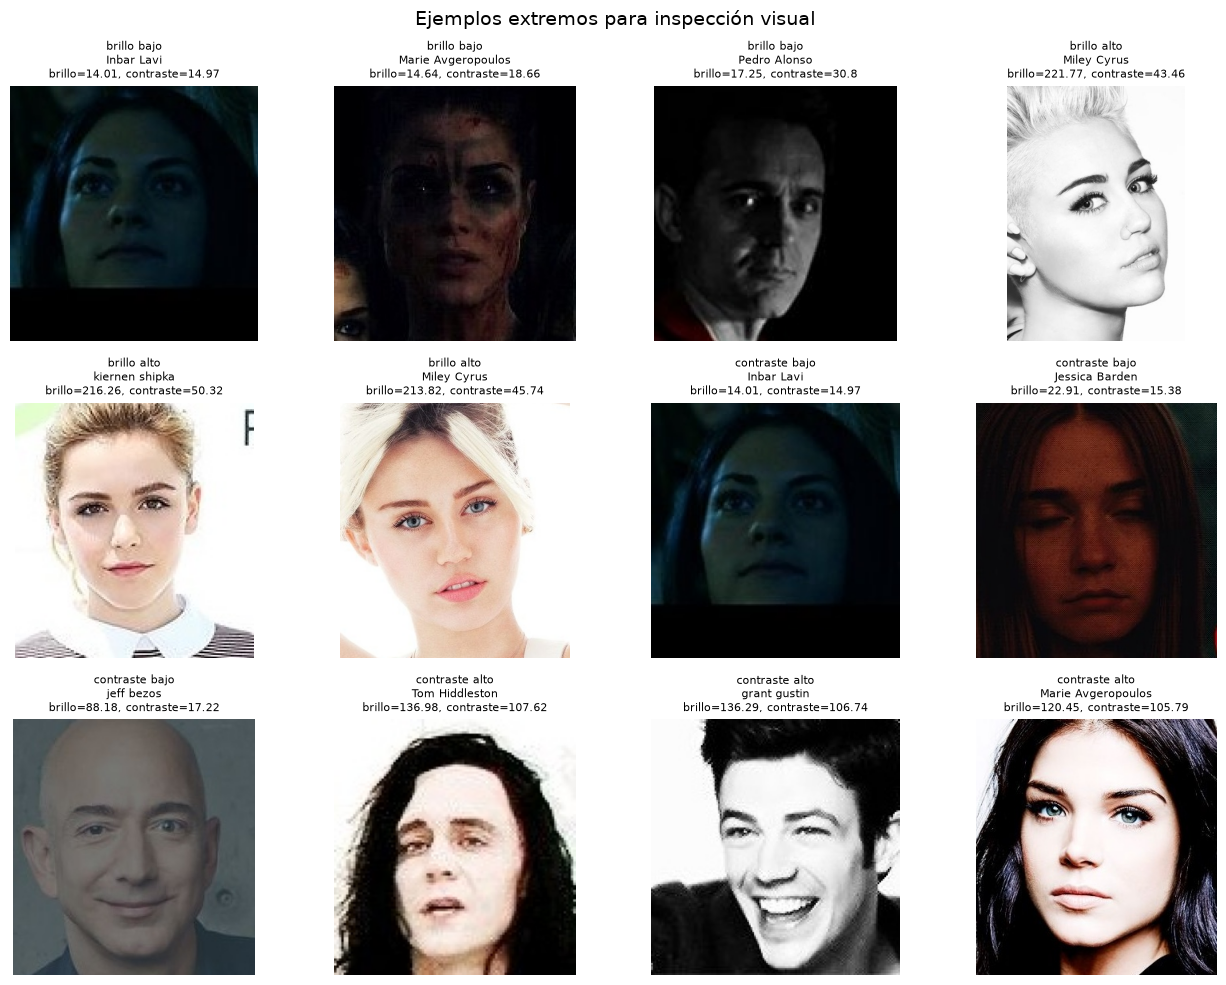

In [37]:
# Casos difíciles: tres imágenes oscuras, tres brillantes, tres de bajo contraste y tres de alto contraste.
difficult_examples = pl.concat(
    [
        readable.sort("brightness").head(3).with_columns(pl.lit("brillo bajo").alias("case")),
        readable.sort("brightness", descending=True).head(3).with_columns(pl.lit("brillo alto").alias("case")),
        readable.sort("contrast").head(3).with_columns(pl.lit("contraste bajo").alias("case")),
        readable.sort("contrast", descending=True).head(3).with_columns(pl.lit("contraste alto").alias("case")),
    ]
 )

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for axis, row in zip(axes.flat, difficult_examples.iter_rows(named=True)):
    with Image.open(DATA_DIR / row["path"]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(
        f"{row['case']}\n{row['identity']}\nbrillo={row['brightness']}, contraste={row['contrast']}",
        fontsize=8,
    )
    axis.axis("off")

for axis in axes.flat[len(difficult_examples):]:
    axis.axis("off")

fig.suptitle("Ejemplos extremos para inspección visual", fontsize=14)
fig.tight_layout()
plt.show()